# Instructor solution notebook — sequential SOC estimation
Proposed undergraduate laboratory; no learner data or validated absolute SOC. Run from the repository root. All numerical results are conditional on 2.5 Ah, initial SOC 100%, and efficiency 1. The 25 Ah scenario is a sensitivity check only.

In [1]:
from pathlib import Path
import numpy as np,pandas as pd,sys
from sklearn.ensemble import RandomForestRegressor,ExtraTreesRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
import matplotlib.pyplot as plt
out=Path('results'); out.mkdir(exist_ok=True)
source=Path('data/ev_log.csv')
df=pd.read_csv(source)
df.columns=['time','speed','acceleration','voltage','current','power'];df=df.apply(pd.to_numeric).sort_values('time').reset_index(drop=True)
assert len(df)==7323 and not df.isna().any().any() and np.all(np.diff(df.time)==1)
print(df.describe().round(3)); print(df.head())

           time     speed  acceleration   voltage   current     power
count  7323.000  7323.000      7323.000  7323.000  7323.000  7323.000
mean   3662.000    24.084         0.000    71.276     0.544    38.758
std    2114.112    16.951         5.289     0.189     0.483    34.391
min       1.000     0.000        -8.700    70.800    -0.700   -49.980
25%    1831.500     6.500        -4.400    71.100     0.000     0.000
50%    3662.000    27.100         0.000    71.400     0.500    35.750
75%    5492.500    38.600         2.900    71.400     0.900    64.260
max    7323.000    54.300        23.000    71.500     1.800   128.520
   time  speed  acceleration  voltage  current  power
0   1.0    0.0           0.0     71.4      0.0    0.0
1   2.0    0.0           0.0     71.4      0.0    0.0
2   3.0    0.0           0.0     71.4      0.0    0.0
3   4.0    0.0           0.0     71.4      0.0    0.0
4   5.0    0.0           0.0     71.4      0.0    0.0


## 1. Audit and signed integration
Positive current discharges the battery. The first record contributes zero elapsed time. The right-endpoint integration convention is used throughout. Voltage and current are logged values, not independently calibrated instrument specifications.

Net Ah: 1.106861111111104 Net Wh: 78.83975833333334
Distance-equivalent (km): 48.99072222222222
Final SOC (2.5, 25 Ah): 55.72555555555505 95.57255555555558


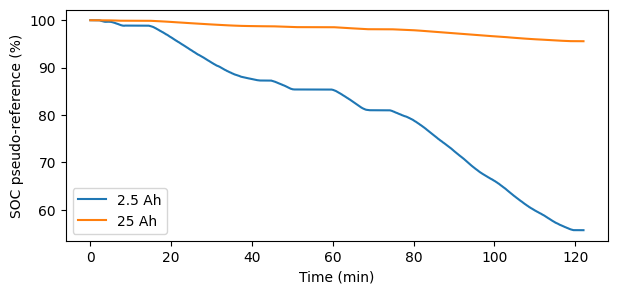

In [2]:
dt=np.r_[0,np.diff(df.time)]; y=-100*df.current.to_numpy()*dt/(3600*2.5);soc=100+np.cumsum(y)
charge=np.cumsum(df.current.to_numpy()*dt)/3600
print('Net Ah:',charge[-1], 'Net Wh:', np.sum(df.power*dt)/3600)
print('Distance-equivalent (km):',np.sum(df.speed*dt)/3600)
print('Final SOC (2.5, 25 Ah):',soc[-1],100-100*charge[-1]/25)
plt.figure(figsize=(7,3)); plt.plot(df.time/60,soc,label='2.5 Ah'); plt.plot(df.time/60,100-100*charge/25,label='25 Ah'); plt.xlabel('Time (min)'); plt.ylabel('SOC pseudo-reference (%)'); plt.legend(); plt.show()

## 2. Causal features and model setup
Use only voltage, speed, acceleration and past/current values. Current and power are excluded because they directly determine the reference increments. This is contemporaneous state estimation, not advance forecasting.

In [3]:
f=df[['speed','acceleration','voltage']];X=pd.concat([f,f.shift().fillna(f),f.rolling(5,min_periods=1).mean()],axis=1).to_numpy()
models={'Mean discharge rate':None,'Linear regression':LinearRegression(),'Random forest':RandomForestRegressor(n_estimators=200,min_samples_leaf=3,max_features=.8,random_state=42,n_jobs=2),'Extra trees':ExtraTreesRegressor(n_estimators=200,min_samples_leaf=3,max_features=.8,random_state=42,n_jobs=2),'KNN':make_pipeline(StandardScaler(),KNeighborsRegressor(n_neighbors=25,weights='distance'))}
cols=['Model','MAE (pp)','RMSE (pp)','R2','Final error (pp)','Increment MAE (pp)']
def run(a,b):
 rows=[];pred={}
 for name,m in models.items():
  yp=np.full(b-a,y[:a].mean()) if m is None else m.fit(X[:a],y[:a]).predict(X[a:b]);p=soc[a-1]+np.cumsum(yp);r=soc[a:b];pred[name]=p
  rows.append([name,mean_absolute_error(r,p),np.sqrt(mean_squared_error(r,p)),r2_score(r,p),p[-1]-r[-1],mean_absolute_error(y[a:b],yp)])
 return pd.DataFrame(rows,columns=cols),pred

## 3. Chronological holdout
The final 1,465 rows are reserved for evaluation. Reconstruct from the last training pseudo-reference; do not reinitialize from the test labels.

In [4]:
s=int(len(df)*.8);m,p=run(s,len(df));m.to_csv(out/'holdout_metrics.csv',index=False);print('holdout',s,len(df)-s,soc[s-1],soc[-1]);print(m.to_string(index=False));print(df.describe());print('unique',df.voltage.nunique(),df.current.nunique(),'Ah',sum(df.current*dt)/3600,'Wh',sum(df.power*dt)/3600,'distance',sum(df.speed*dt)/3600)
print(m.round(3).to_string(index=False))

holdout 5858 1465 67.29666666666594 55.72555555555505
              Model  MAE (pp)  RMSE (pp)       R2  Final error (pp)  Increment MAE (pp)
Mean discharge rate  2.716740   3.059768 0.321349          3.392486            0.004712
  Linear regression  0.200958   0.243707 0.995695         -0.357486            0.003088
      Random forest  0.256255   0.316186 0.992753         -0.559743            0.003100
        Extra trees  0.288803   0.351775 0.991030         -0.628290            0.003093
                KNN  0.412328   0.512613 0.980952         -1.028805            0.003180
              time        speed  ...      current        power
count  7323.000000  7323.000000  ...  7323.000000  7323.000000
mean   3662.000000    24.083927  ...     0.544135    38.757767
std    2114.112343    16.950796  ...     0.482900    34.390983
min       1.000000     0.000000  ...    -0.700000   -49.980000
25%    1831.500000     6.500000  ...     0.000000     0.000000
50%    3662.000000    27.100000  ...    

## 4. Expanding-window validation
Three validation blocks are contained entirely in the training segment. The fold standard deviations are sample standard deviations, not confidence intervals or independent experimental replicates.

In [5]:
folds=[]
for a,b in [(2929,3905),(3905,4881),(4881,5858)]:
 z,_=run(a,b);z.insert(0,'Train samples',a);z.insert(1,'Test samples',b-a);folds.append(z)
cv=pd.concat(folds);cv.to_csv(out/'rolling_origin_metrics.csv',index=False);summ=cv.groupby('Model',sort=False)[cols[1:]].agg(['mean','std']);summ.to_csv(out/'rolling_origin_summary.csv');print(summ.to_string())

                     MAE (pp)           RMSE (pp)                  R2           Final error (pp)           Increment MAE (pp)          
                         mean       std      mean       std      mean       std             mean       std               mean       std
Model                                                                                                                                  
Mean discharge rate  1.728184  1.432312  2.003960  1.671027 -1.454154  2.922619         1.728007  4.226435           0.005155  0.001329
Linear regression    0.102573  0.092921  0.128780  0.128396  0.994929  0.002150        -0.224151  0.345822           0.002134  0.000950
Random forest        0.313756  0.446601  0.377169  0.545742  0.963457  0.054562         0.598823  0.979472           0.002221  0.001090
Extra trees          0.233390  0.347461  0.282040  0.423235  0.979365  0.032619         0.441590  0.744576           0.002176  0.001018
KNN                  0.326703  0.487306  0.39236

## 5. Direct absolute-SOC comparison
Compare the three original regressors using the same chronological split.

In [6]:
absrows=[]
for name in ['Random forest','Extra trees','KNN']:
 model=models[name];q=model.fit(X[:s],soc[:s]).predict(X[s:]);absrows.append([name,mean_absolute_error(soc[s:],q),np.sqrt(mean_squared_error(soc[s:],q)),r2_score(soc[s:],q),q.min(),q.max()])
a=pd.DataFrame(absrows,columns=['Model','MAE (pp)','RMSE (pp)','R2','Min SOC','Max SOC']);a.to_csv(out/'absolute_soc_metrics.csv',index=False);print(a.to_string(index=False))

        Model  MAE (pp)  RMSE (pp)         R2   Min SOC   Max SOC
Random forest 19.535051  21.246561 -31.722538 69.398194 91.106699
  Extra trees 19.085697  20.744931 -30.195627 69.537442 91.867704
          KNN 20.109793  21.951950 -33.931393 69.592679 91.353544


## 6. Reconstruction and cumulative error
Positive signed error is overestimation relative to the pseudo-reference. Inspect the time path, not only the endpoint.

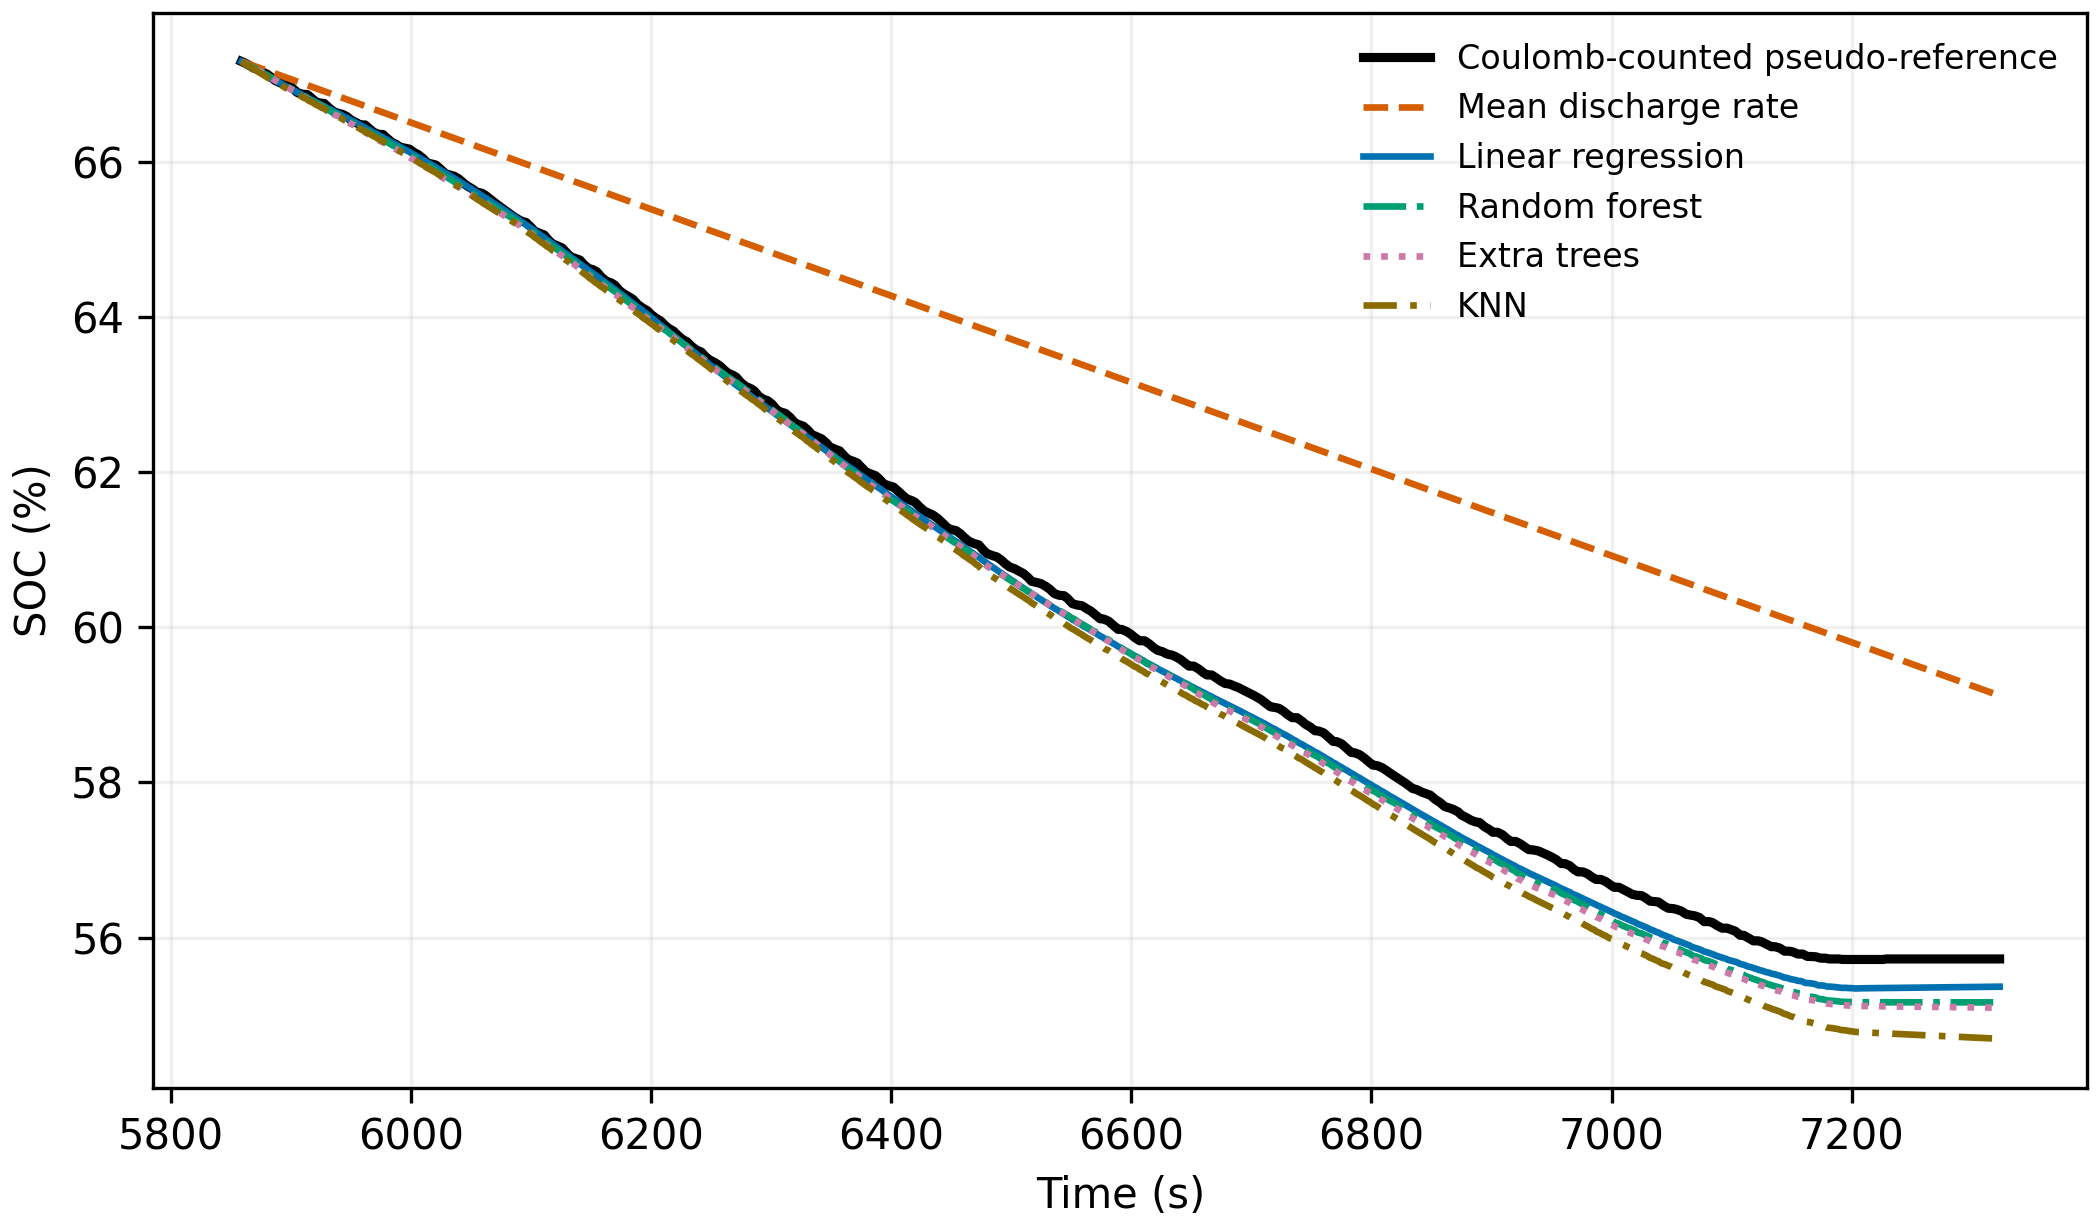

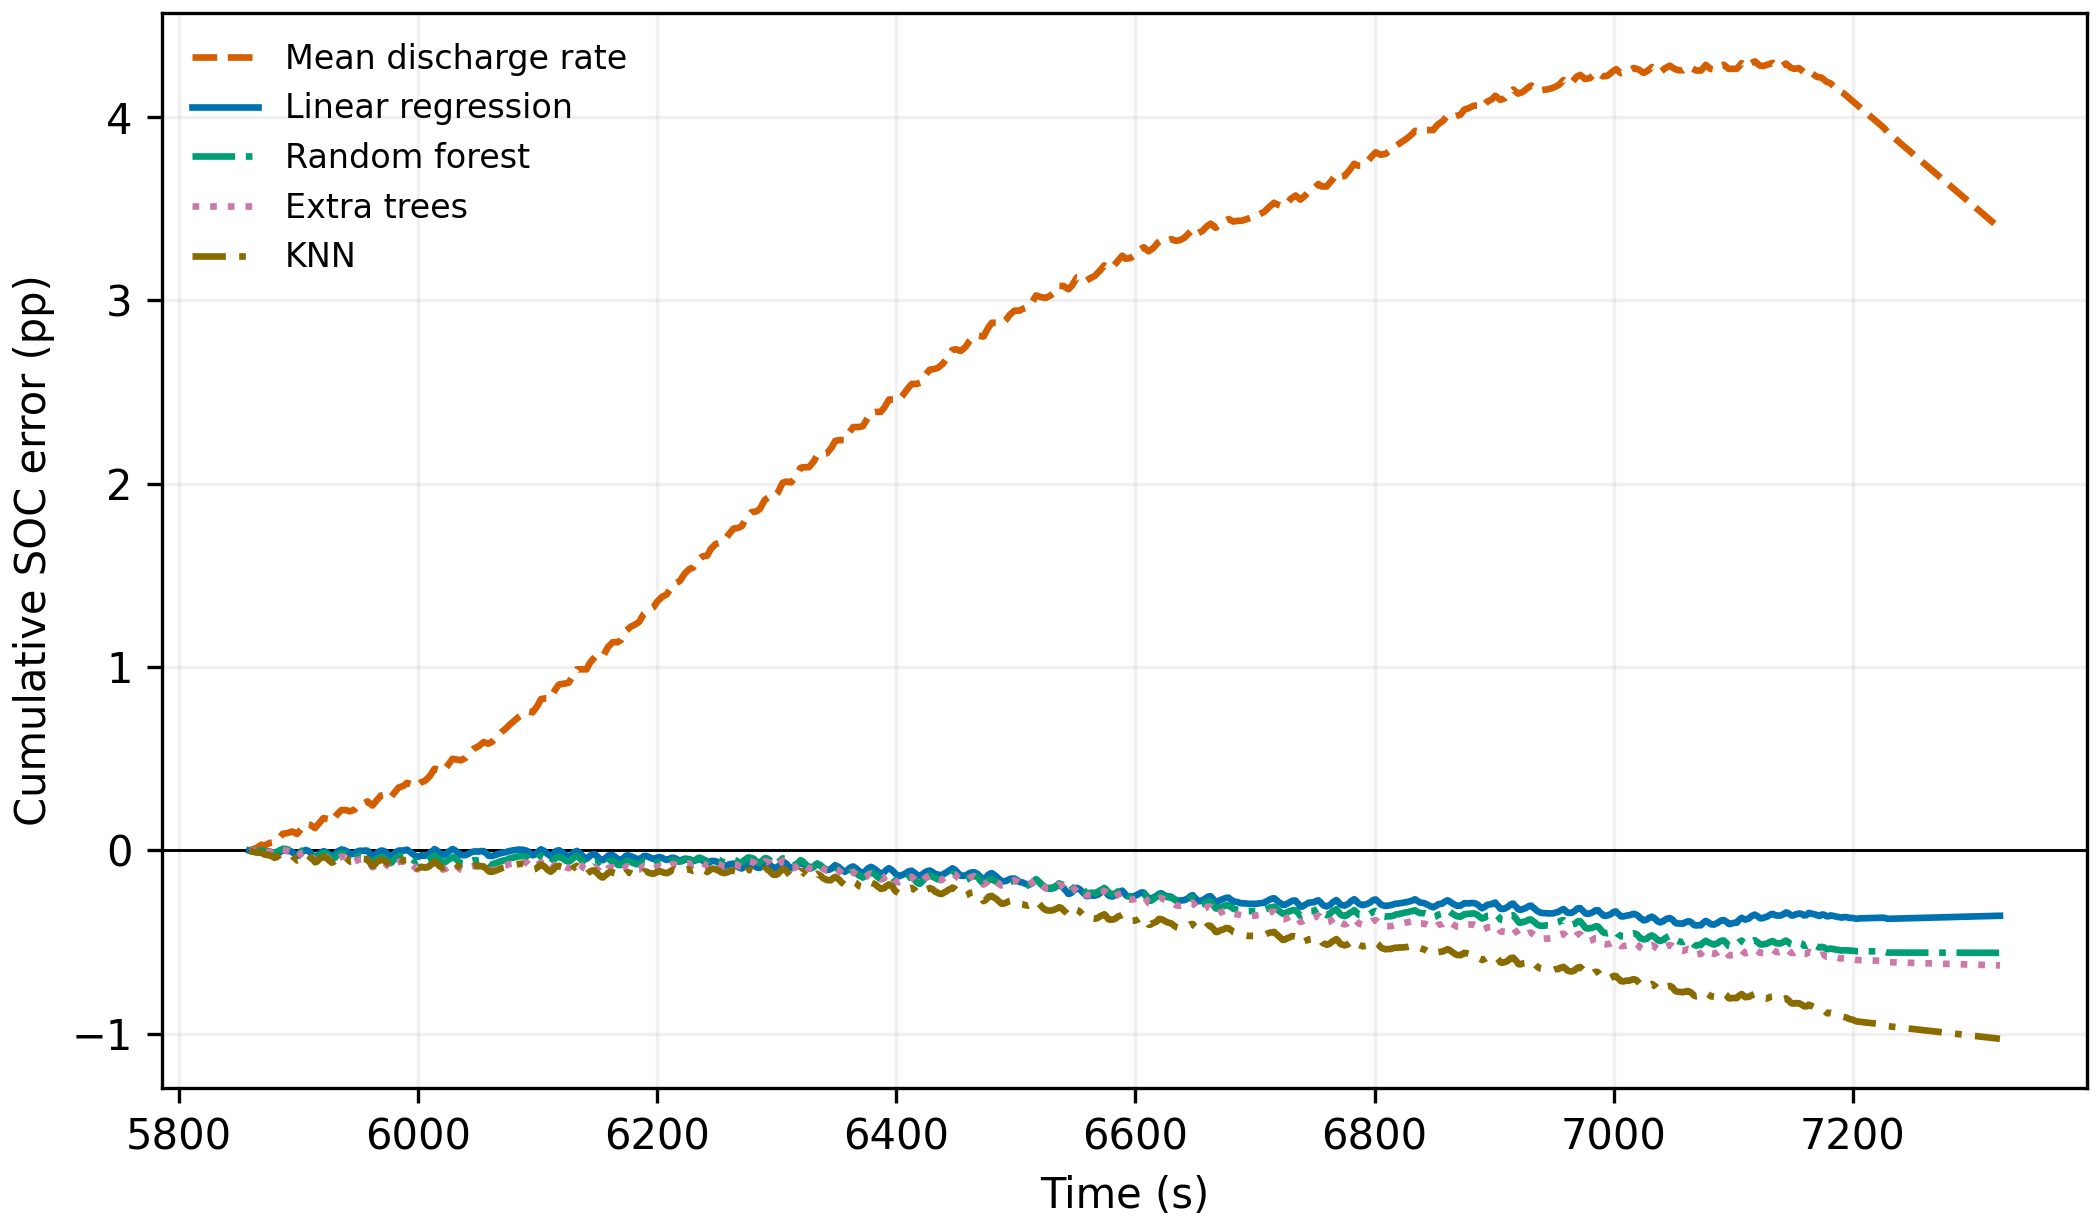

In [7]:
t=df.time.iloc[s:].to_numpy();pred=pd.DataFrame({'Time (s)':t,'SOC_CC (%)':soc[s:]})
for name,q in p.items():pred[name]=q;pred[name+' error (pp)']=q-soc[s:]
pred.to_csv(out/'holdout_predictions.csv',index=False)
for error,name in [(False,'Figure_4_SOC_reconstruction.png'),(True,'Figure_5_cumulative_error.png')]:
 fig,ax=plt.subplots(figsize=(7,4.1),layout='constrained')
 if not error:ax.plot(t,soc[s:],color='black',lw=2.2,label='Coulomb-counted pseudo-reference')
 else:ax.axhline(0,color='black',lw=.7)
 for (label,q),style,c in zip(p.items(),['--', '-', '-.', ':', (0, (5, 2, 1, 2))],['#D55E00', '#0072B2', '#009E73', '#CC79A7', '#8A6B00']):ax.plot(t,q-soc[s:] if error else q,label=label,ls=style,color=c,lw=1.6)
 ax.set(xlabel='Time (s)',ylabel='Cumulative SOC error (pp)' if error else 'SOC (%)');ax.grid(alpha=.18);ax.legend(fontsize=8,frameon=False);fig.savefig(out/name,dpi=300);plt.close(fig)
from IPython.display import Image, display
display(Image(filename=str(out/'Figure_4_SOC_reconstruction.png')))
display(Image(filename=str(out/'Figure_5_cumulative_error.png')))

## 7. Interpretation
The linear baseline has the smallest reconstructed holdout error in this record (approximately 0.201 pp MAE). A constant-rate baseline is weaker but still follows a descending trajectory. Direct nonlinear regression extrapolates poorly. Neither agreement nor high R² validates absolute SOC. A battery nameplate, chemistry, series/parallel arrangement, independently validated reference, sensor calibration and documented operating conditions are required for stronger physical claims. The design remains unpiloted.